# Further analysis ES cells


In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "../../")

import builtins
builtins.NAMING = "new"
import scipy.stats as stats


from RealTrace_paper_analysis.plotting_src.header_settings import *

from RealTrace_paper_analysis.plotting_src.plot_correlations_from_npz import *

from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.simulations.cells_simulation import * # you might need to change these two line, such that you can use read ggp_run

from RealTrace_paper_analysis.plotting_src.cells_utils import *
from RealTrace_paper_analysis.plotting_src.read_utils import *
from RealTrace_paper_analysis.plotting_src.naive_rates import *



%config InlineBackend.figure_format ='retina'


/var/folders/_h/4605456d743bfjqsq6r1jcdm0000gp/T/ipykernel_5966/1372135230.py:9: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 1.21.0)
  import scipy.stats as stats


header_setting.py: using new naming


In [2]:
def get_mean_growth_rate(cells):
    mean_lambda = np.sum(np.concatenate([np.array(cell.mean_l)/np.array(cell.cov_ll) for cell in cells])) \
                /np.sum(np.concatenate([1./np.array(cell.cov_ll) for cell in cells]))
    return mean_lambda### Reading files

In [4]:
input_dir = "../../data_realtrace_paper/esc_data"

corralations_filenames = get_input_files(input_dir, keyword="correlations", ext=".npz")

# Filter if wanted
# corralations_filenames = [cf for cf in corralations_filenames if not "_rp" in cf]
# corralations_filenames = [cf for cf in corralations_filenames if not "_rr" in cf]
corralations_filenames = [cf for cf in corralations_filenames if not "_6300_" in cf]

# conditions = ["acetate", "glycerol", "glucose", "glucoseaa"]
# promoters = ['hi1', 'hi3', 'med2', 'med3', 'rrnB', 'rpsB', 'rpmB', 'rplN']

corr_dict = {}
gamma_lambdas = {}
mean_lambdas = {}
mean_qs = {}
gamma_qs = {}
mean_sq_conc = {}

for cf in corralations_filenames:
    data = np.load(cf, allow_pickle=True)

    data_set_name = re.split('_f\d', cf.split('/')[-1] )[0]
    print(data_set_name, end="\t") 

    corr_dict[data_set_name] = Correlation_function(data['correlations'])
    corr_to_csv(data['correlations'], cf.replace(".npz", ".csv"))
    
    # Collect relevant parameters 
    gamma_lambdas[data_set_name] = data['gamma_lambda']
    mean_lambdas[data_set_name] = data['mean_lambda']
    
    gamma_qs[data_set_name] = data['gamma_q']
    mean_qs[data_set_name] = data['mean_q']
    
    prediction_file = cf.replace("correlations.npz", "prediction.csv")
    cells = df2ggp_cells(pd.read_csv(prediction_file, skiprows=header_lines(prediction_file), 
                                 dtype={"parent_id":str, "cell_id":str}))
    
    mean_sq_conc[data_set_name] = get_mean_growth_rate(cells)**2


MCFT-Raly_B_mod1	

In [ ]:
def plot_cross_coor(corr_orig, x, y, 
                    mean_lambda,
                    gamma_lambda, 
                    gamma_q,
                    plot_file=None, 
                    normalize=None,
                    xlim=[None, None],
                    ylim=[None,None], 
                    ylabel=None,
                    log=False, 
                    fit=False, 
                    highlight_x0=False,
                    highlight_y0=False,
                    corr_type="cov", 
                    color=None,
                    legend=True,
                    title=None):

    
    correlation_function = copy.deepcopy(corr_orig)
    
    get_func=Correlation_function.get_corr_mle
    get_err_func=Correlation_function.get_corr_mle_err

    # =========== figure =========== #

    fig, ax = plt.subplots(1,3, figsize=(FULL_SIZE, FULL_HEIGHT), sharey=False, sharex=False)
    ax = ax.ravel()

    for a in ax:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

    dts = correlation_function.dt

    # =========== correlation =========== #
    
    rs = get_func(correlation_function, "l(t+dt)", "l(t)")
    errs = get_err_func(correlation_function, "l(t+dt)", "l(t)")

    ax[0].set_title(r"auto-correlation $C[\lambda(t^\prime),\lambda(t)]$")
    ax[0].plot(dts, rs, lw=2, color=color, alpha=0.8)
    ax[0].plot(dts, np.exp(-gamma_lambda*dts), 
               ls="--", 
               color="tab:grey",
               label="$1/\\gamma_\lambda=${:.2f}".format(1/gamma_lambda))
    ax[0].fill_between(dts, rs-errs, rs+errs, color=color, alpha=0.2)

    ax[0].axhline(0,color="tab:grey", lw=1)
    ax[0].axvline(0,color="tab:grey", lw=1)
    ax[0].set_ylim(0.03,1)
    ax[0].set_xlim(0, 5)
    ax[0].set_yscale('log')
    ax[0].legend()
    ##
    rs = get_func(correlation_function, "q(t+dt)", "q(t)")
    errs = get_err_func(correlation_function, "q(t+dt)", "q(t)")

    ax[1].set_title(r"auto-correlation $C[q(t^\prime),q(t)]$")
    ax[1].plot(dts, rs, lw=2, color=color, alpha=0.8)
    ax[1].plot(dts, np.exp(-gamma_q*dts), 
           ls="--", 
           color="tab:grey",
           label="$1/\\gamma_q=${:.2f}".format(1/gamma_q))
    ax[1].fill_between(dts, rs-errs, rs+errs, color=color, alpha=0.2)

    ax[1].axhline(0,color="tab:grey", lw=1)
    ax[1].axvline(0,color="tab:grey", lw=1)
    ax[1].set_ylim(0.03,1)
    ax[1].set_xlim(0, 5)
    ax[1].set_yscale('log')
    ax[1].legend()

    ##
    
    
    rs = get_func(correlation_function, "q(t+dt)", "l(t)")
    errs = get_err_func(correlation_function, "q(t+dt)", "l(t)")

    ax[2].set_title(r"cross-correlation $C[q(t^\prime),\lambda(t)]$")
    ax[2].plot(dts, rs, lw=2, color=color, alpha=0.8)
    ax[2].fill_between(dts, rs-errs, rs+errs, color=color, alpha=0.2)

    ax[2].axhline(0,color="tab:grey", lw=1)
    ax[2].axvline(0,color="tab:grey", lw=1)
    ax[2].set_ylim(-0.1, 0.3)
    ax[2].set_xlim(-5, 5)

    
    # =========== figure =========== #
    
    for i, _ in enumerate(ax):
        # ax[i].xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=1))
        ax[i].xaxis.set_minor_locator(matplotlib.ticker.MultipleLocator(base=1))
        ax[i].yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=0.2))
        ax[i].yaxis.set_minor_locator(matplotlib.ticker.MultipleLocator(base=0.1))


    ax[0].set_ylabel("Correlation")
    for a in ax:
        a.set_xlabel(r'time lag $t^\prime-t$ (h)')

    fig.tight_layout()
    if plot_file != None:
        print("Saved in", plot_file)
        fig.savefig(plot_file, dpi=300, facecolor="white", bbox_inches="tight")
        plt.show()
        
    else:
        plt.show()
    plt.close()
            
        
        
for data_set in corr_dict.keys():
    
    gamma_lambdas[data_set_name] = data['gamma_lambda']
    mean_lambdas[data_set_name] = data['mean_lambda']
    
    gamma_qs[data_set_name] = data['gamma_q']
    
    
    plot_cross_coor(corr_dict[data_set], 
                    "q(t+dt)", "l(t)", 
                    mean_lambdas[data_set],
                    gamma_lambdas[data_set],
                    gamma_qs[data_set],
                    ylim=[-0.5, 0.5], 
                    xlim=[-1.5,1.5], 
                    # log=True, 
                    corr_type="corr",
                    legend=False, 
                    color="tab:grey",
                    title=None,
                    plot_file="../../figures_for_method_paper/supp/esc/esc_correlation_functions.pdf")





## Noise across cell cycle

In [6]:
filename_esc = "../../data_realtrace_paper/esc_data/MCFT-Raly_B_mod1_f01234578910_b_prediction.csv"
data_esc = pd.read_csv(filename_esc, skiprows=header_lines(filename_esc))
esc_data = df2ggp_cells(data_esc)

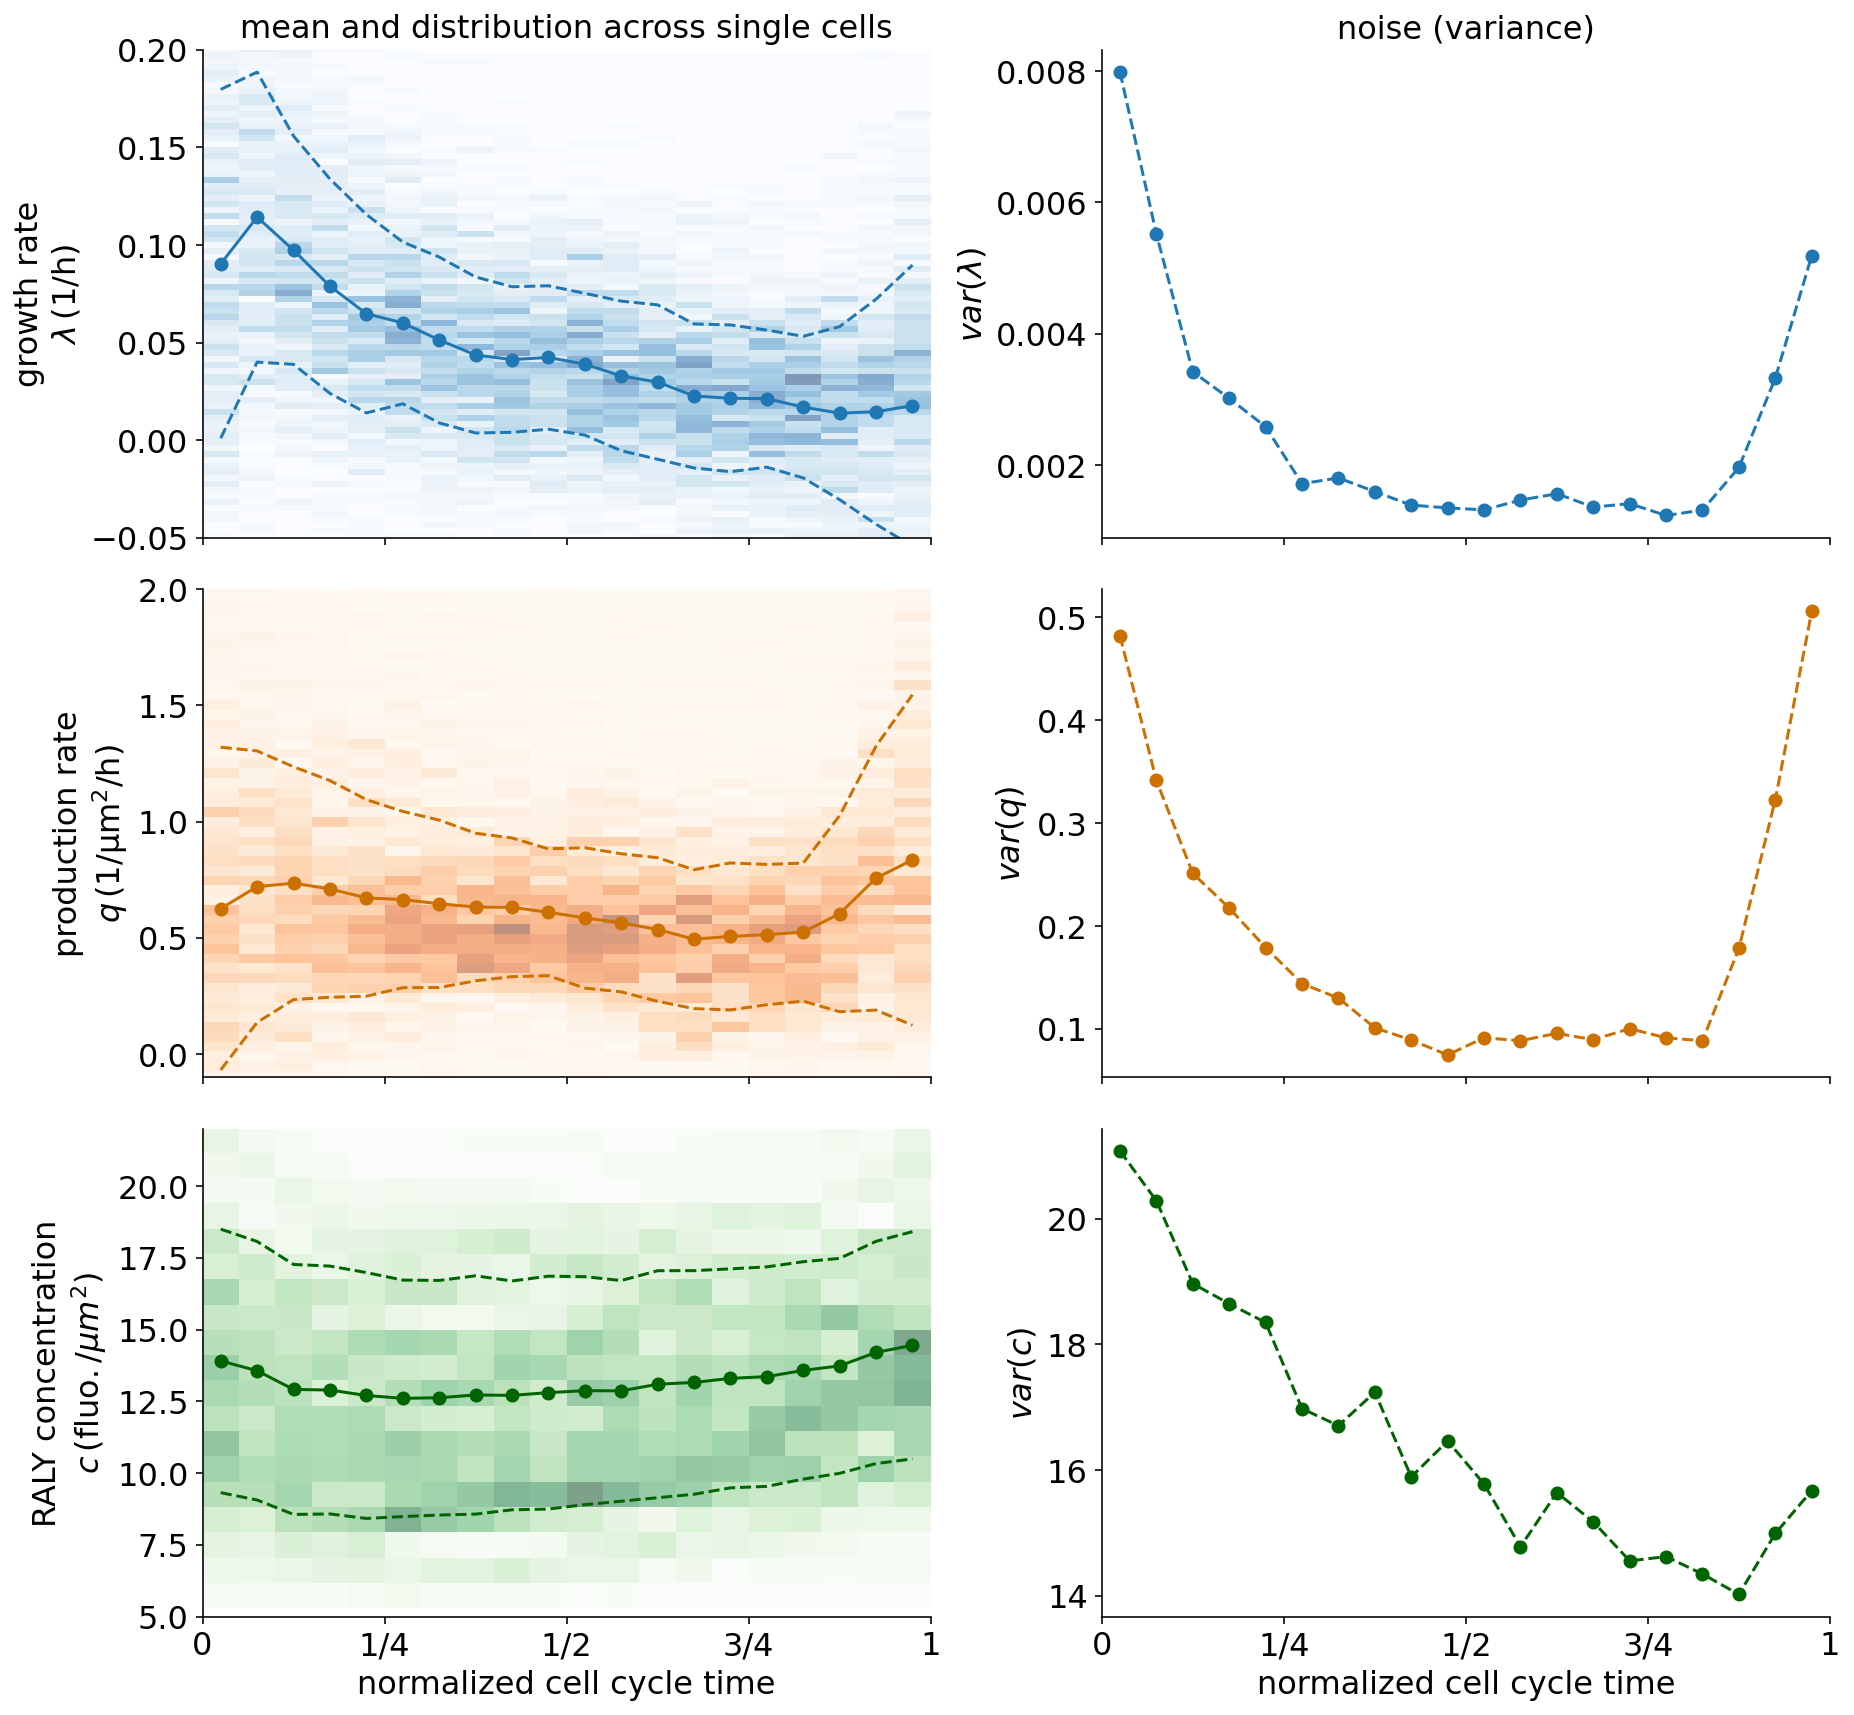

array([<AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>,
       <AxesSubplot:>, <AxesSubplot:>], dtype=object)

In [8]:
def plot_cc_variance_lqc(cells, time_unit=("h", 1), 
                           skip_row=13,
                           xlim=[None, None], 
                           outfile=None, 
                           show=True, 
                           mark_transition=False,
                           color=["tab:blue"]*100,
                        ignore_errors=False):
                         
    fig, axes = plt.subplots(3, 2, figsize=(FULL_SIZE,FULL_HEIGHT*3), sharex=True)

    ax = axes.ravel()


    
    collect_time = []
    for i, cell in enumerate(cells):
        time =cell.time
        time = (time-time[0])/(time[-1]-time[0])        
        collect_time.append(time)
    

    color_l ="tab:blue"
    color_q ="#cc7000"
    color_c ="darkgreen"
    
        
    bins=20
    bins_time = bins
    collect_time = np.concatenate(collect_time)

    
    ##########
    collect_mean_l = np.concatenate([cell.mean_l for cell in cells])
    mean_l, bin_edges,_ = stats.binned_statistic(collect_time, collect_mean_l, statistic='mean', bins=bins)
    std_l, _,_ = stats.binned_statistic(collect_time, collect_mean_l, statistic='std', bins=bins)

    ax[0].plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_l, marker="o", color=color_l)
    ax[0].hist2d(collect_time, collect_mean_l, cmap="Blues", 
                 bins=[bins_time, np.arange(np.min(collect_mean_l), 
                                 np.max(collect_mean_l), 
                                 np.mean(collect_mean_l)/15 )  ], 
                 density=False, alpha=0.5)
    ax[0].plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_l-std_l, color=color_l, alpha=1, ls="--")
    ax[0].plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_l+std_l, color=color_l, alpha=1, ls="--")
    
    ##########
    collect_mean_q = np.concatenate([cell.mean_q for cell in cells])
    mean_q, bin_edges,_ = stats.binned_statistic(collect_time, collect_mean_q, statistic='mean', bins=bins)
    std_q, _,_ = stats.binned_statistic(collect_time, collect_mean_q, statistic='std', bins=bins)

    ax[2].plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_q, marker="o", color=color_q)
    ax[2].hist2d(collect_time, collect_mean_q, cmap="Oranges", 
                 bins=[bins_time, np.arange(np.min(collect_mean_q), 
                                 np.max(collect_mean_q), 
                                 np.mean(collect_mean_q)/15 )  ], 
                 density=False, alpha=0.5)
    ax[2].plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_q-std_q, color=color_q, alpha=1, ls="--")
    ax[2].plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_q+std_q, color=color_q, alpha=1, ls="--")
    
    ##########
    collect_mean_c = np.concatenate([cell.mean_g/np.exp(cell.mean_x) for cell in cells])
    mean_c, bin_edges,_ = stats.binned_statistic(collect_time, collect_mean_c, statistic='mean', bins=bins)
    std_c, _,_ = stats.binned_statistic(collect_time, collect_mean_c, statistic='std', bins=bins)

    ax[4].plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_c, marker="o", color=color_c)
    ax[4].hist2d(collect_time, collect_mean_c, cmap="Greens", 
                 bins=[bins_time, np.arange(np.min(collect_mean_c), 
                                 np.max(collect_mean_c), 
                                 np.mean(collect_mean_c)/15 ) ], 
                 density=False, alpha=0.5)
    ax[4].plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_c-std_c, color=color_c, alpha=1, ls="--")
    ax[4].plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_c+std_c, color=color_c, alpha=1, ls="--")
    # ax[2].fill_between(bin_edges[:-1]+np.diff(bin_edges)/2, mean_c-std_c, mean_c+std_c, color=color_c, alpha=0.2)
    
    
    ax[0].set_title("mean and distribution across single cells")   
    ax[1].set_title(r"noise (variance)")   
    
    ##########
    ax[1].plot(bin_edges[:-1]+np.diff(bin_edges)/2, std_l**2, marker="o", color=color_l, alpha=1, ls="--")
    ax[3].plot(bin_edges[:-1]+np.diff(bin_edges)/2, std_q**2, marker="o", color=color_q, alpha=1, ls="--")
    ax[5].plot(bin_edges[:-1]+np.diff(bin_edges)/2, std_c**2, marker="o", color=color_c, alpha=1, ls="--")


    ax[0].set_ylabel("growth rate\n$\\lambda\,\mathrm{(1/h)}$")   
    ax[2].set_ylabel("production rate\n$q\,\mathrm{(1/\mu  m^2/h)}$")   
    ax[4].set_ylabel("RALY concentration\n$c\, (\mathrm{fluo.}/\mu m^2)$")   

    ax[1].set_ylabel(r"$var(\lambda)$")
    ax[3].set_ylabel(r"$var(q)$")
    ax[5].set_ylabel(r"$var(c)$")

    ax[4].set_xlabel("normalized cell cycle time")  
    ax[5].set_xlabel("normalized cell cycle time")  
    
    ax[0].set_ylim(-0.05, 0.2)
    ax[2].set_ylim(-0.1, 2.0)
    ax[4].set_ylim(5, 22)

    for a in list(ax) :
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()   
        a.set_xticks(np.arange(0, 1.25, 0.25))
        a.set_xticklabels(["0", "1/4", "1/2", "3/4", "1"])
        
    fig.tight_layout()
    
    if outfile != None:
        plt.show()
        fig.savefig(outfile, bbox_inches='tight')
    elif show:
        plt.show()
    fig.clear()
    plt.close(fig)
    return ax


plot_cc_variance_lqc(esc_data) #outfile="../../ESCs_Suter_lab/cc_variance_lqc.pdf")

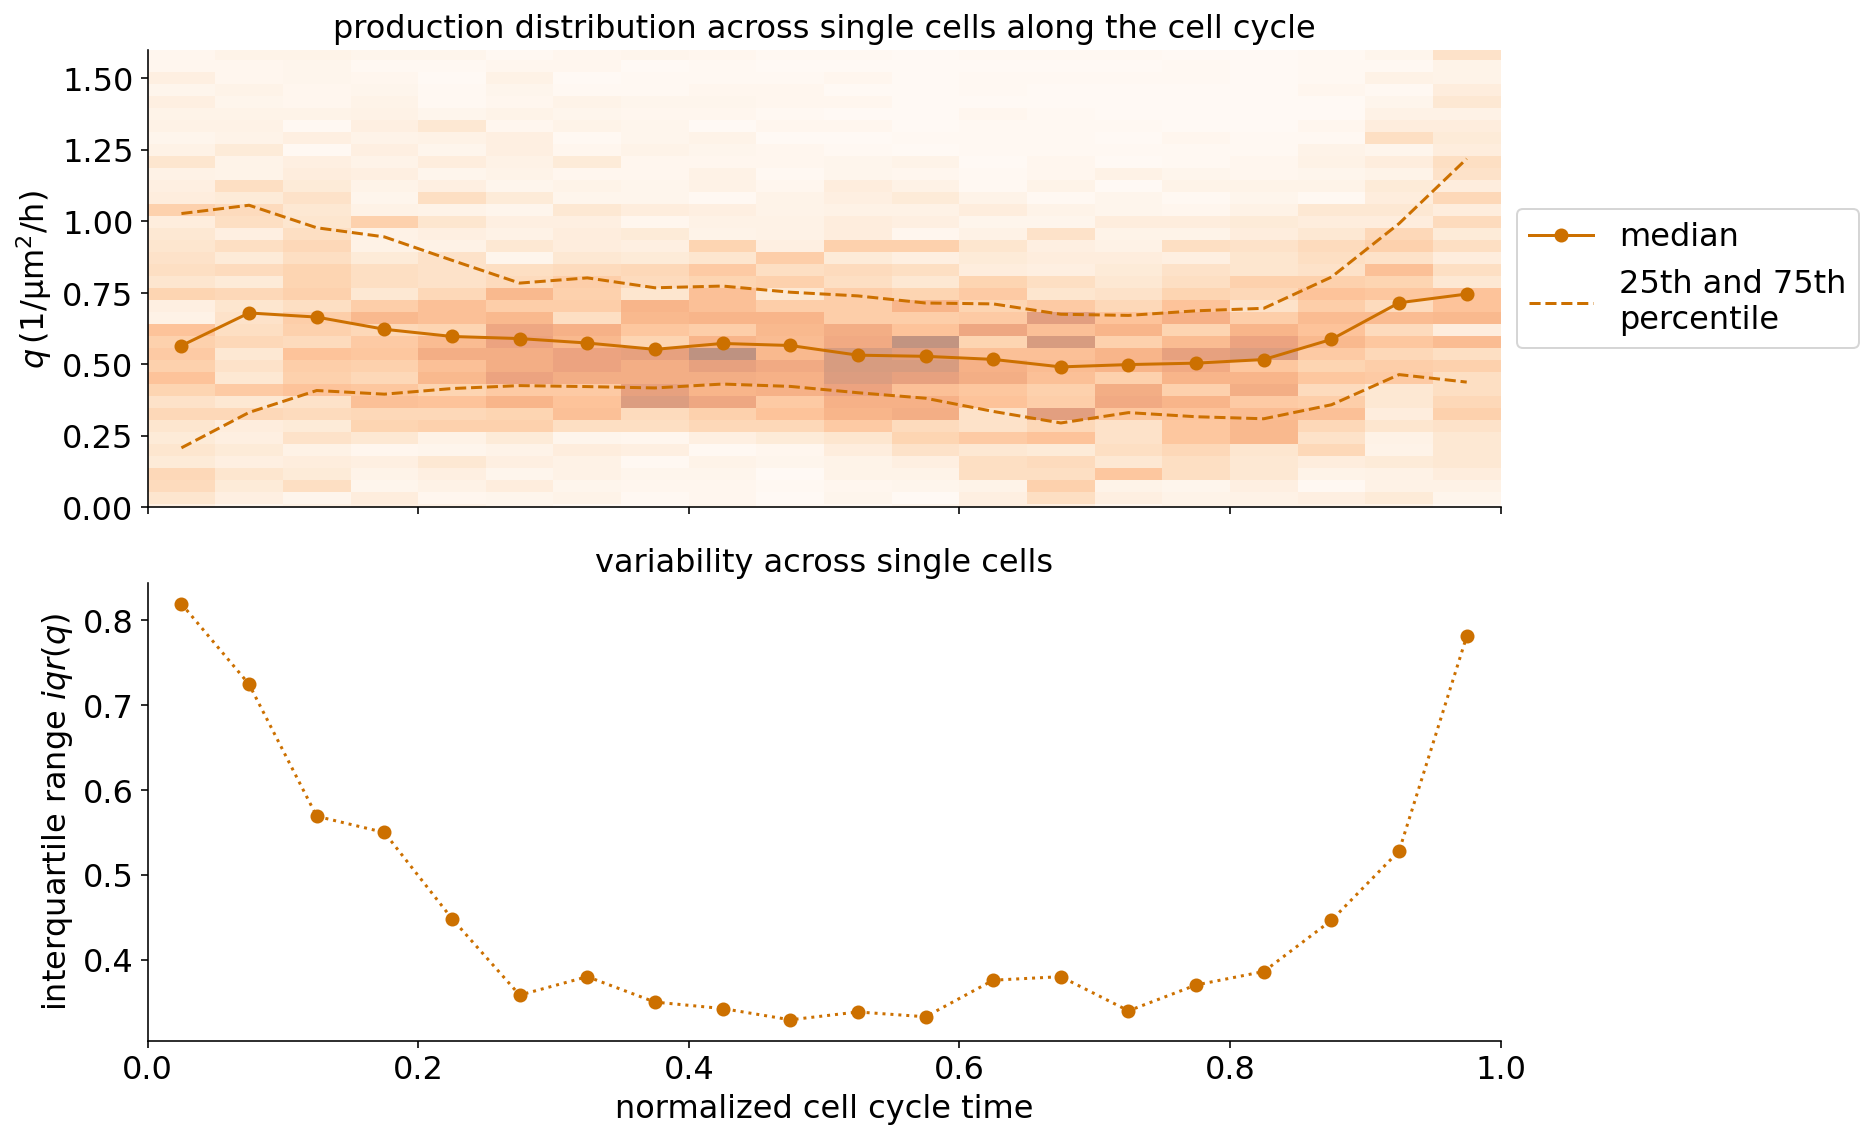

array([<AxesSubplot:>, <AxesSubplot:>], dtype=object)

In [9]:
def quartile1(arr):
    return np.percentile(arr, 25)

def quartile3(arr):
    return np.percentile(arr, 75)

def plot_cc_variance_q(cells, time_unit=("h", 1), 
                           skip_row=13,
                           xlim=[None, None], 
                           outfile=None, 
                           show=True, 
                           mark_transition=False,
                           color=["tab:blue"]*100,
                        ignore_errors=False):
                         
    fig, axes = plt.subplots(2, 1, figsize=(FULL_SIZE,FULL_HEIGHT*2), sharex=True)

    ax = axes.ravel()


    
    collect_time = []
    for i, cell in enumerate(cells):
        time = np.array(cell.time) / time_unit[1]
        time = (time-time[0])/(time[-1]-time[0])

        color="tab:blue"
        
        # ax[0].plot(time, cell.mean_l, color=color, lw=lw, alpha=0.1)
        # ax[2].plot(time, cell.mean_q, color=color, lw=lw, alpha=0.1)
        # c = cell.mean_g/np.exp(cell.mean_x)
        # ax[4].plot(time, c, color=color, lw=lw, alpha=0.4)
        
        collect_time.append(time)
    
    # color_l ="tab:blue"
    # color_q ="tab:orange"
    # color_c ="tab:green"
    color_l ="tab:blue"
    color_q ="#cc7000"
    color_c ="darkgreen"
    
        
    bins=20
    bins_time = bins
    collect_time = np.concatenate(collect_time)


    ##########
    collect_mean_q = np.concatenate([cell.mean_q for cell in cells])
    mean_q, bin_edges,_ = stats.binned_statistic(collect_time, collect_mean_q, statistic='median', bins=bins)
    std_q, _,_ = stats.binned_statistic(collect_time, collect_mean_q, statistic='std', bins=bins)

    ax[0].hist2d(collect_time, collect_mean_q, cmap="Oranges", 
                 bins=[bins_time, np.arange(np.min(collect_mean_q), 
                                 np.max(collect_mean_q), 
                                 np.mean(collect_mean_q)/15 )  ], 
                 density=False, alpha=0.5)
    
    bin_q1, _, _= stats.binned_statistic(collect_time,collect_mean_q, statistic=quartile1, bins=bins_time)
    bin_q3, _, _= stats.binned_statistic(collect_time,collect_mean_q, statistic=quartile3, bins=bins_time)

    ax[0].plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_q, marker="o", color=color_q, label="median")
    ax[0].plot(bin_edges[:-1]+np.diff(bin_edges)/2, bin_q3, color=color_q, alpha=1, ls="--", label="25th and 75th\npercentile")
    ax[0].plot(bin_edges[:-1]+np.diff(bin_edges)/2, bin_q1, color=color_q, alpha=1, ls="--")
    
    ax[0].set_title("production distribution across single cells along the cell cycle")   
    ax[1].set_title(r"variability across single cells")   
    
    ##########
    ax[1].plot(bin_edges[:-1]+np.diff(bin_edges)/2, bin_q3-bin_q1, marker="o", color=color_q, alpha=1, ls=":")


    ax[0].set_ylabel(r"$q\,\mathrm{(1/\mu  m^2/h)}$")   
    ax[1].set_ylabel(r"interquartile range $iqr(q)$")
    # ax[0].set_xlabel("normalized cell cycle time")  
    ax[1].set_xlabel("normalized cell cycle time")  
    
    ax[0].set_ylim(-0, 1.6)
    
    ax[0].legend(bbox_to_anchor=(1,0.5), loc="center left")


    for a in list(ax) :
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()   
        
    fig.tight_layout()
    
    if outfile != None:
        plt.show()
        fig.savefig(outfile, bbox_inches='tight')
    elif show:
        plt.show()
    fig.clear()
    plt.close(fig)
    return ax


plot_cc_variance_q(esc_data)
                    # outfile="../../figures_for_method_paper/supp/esc/sc_production_across_cell_cycle.pdf")


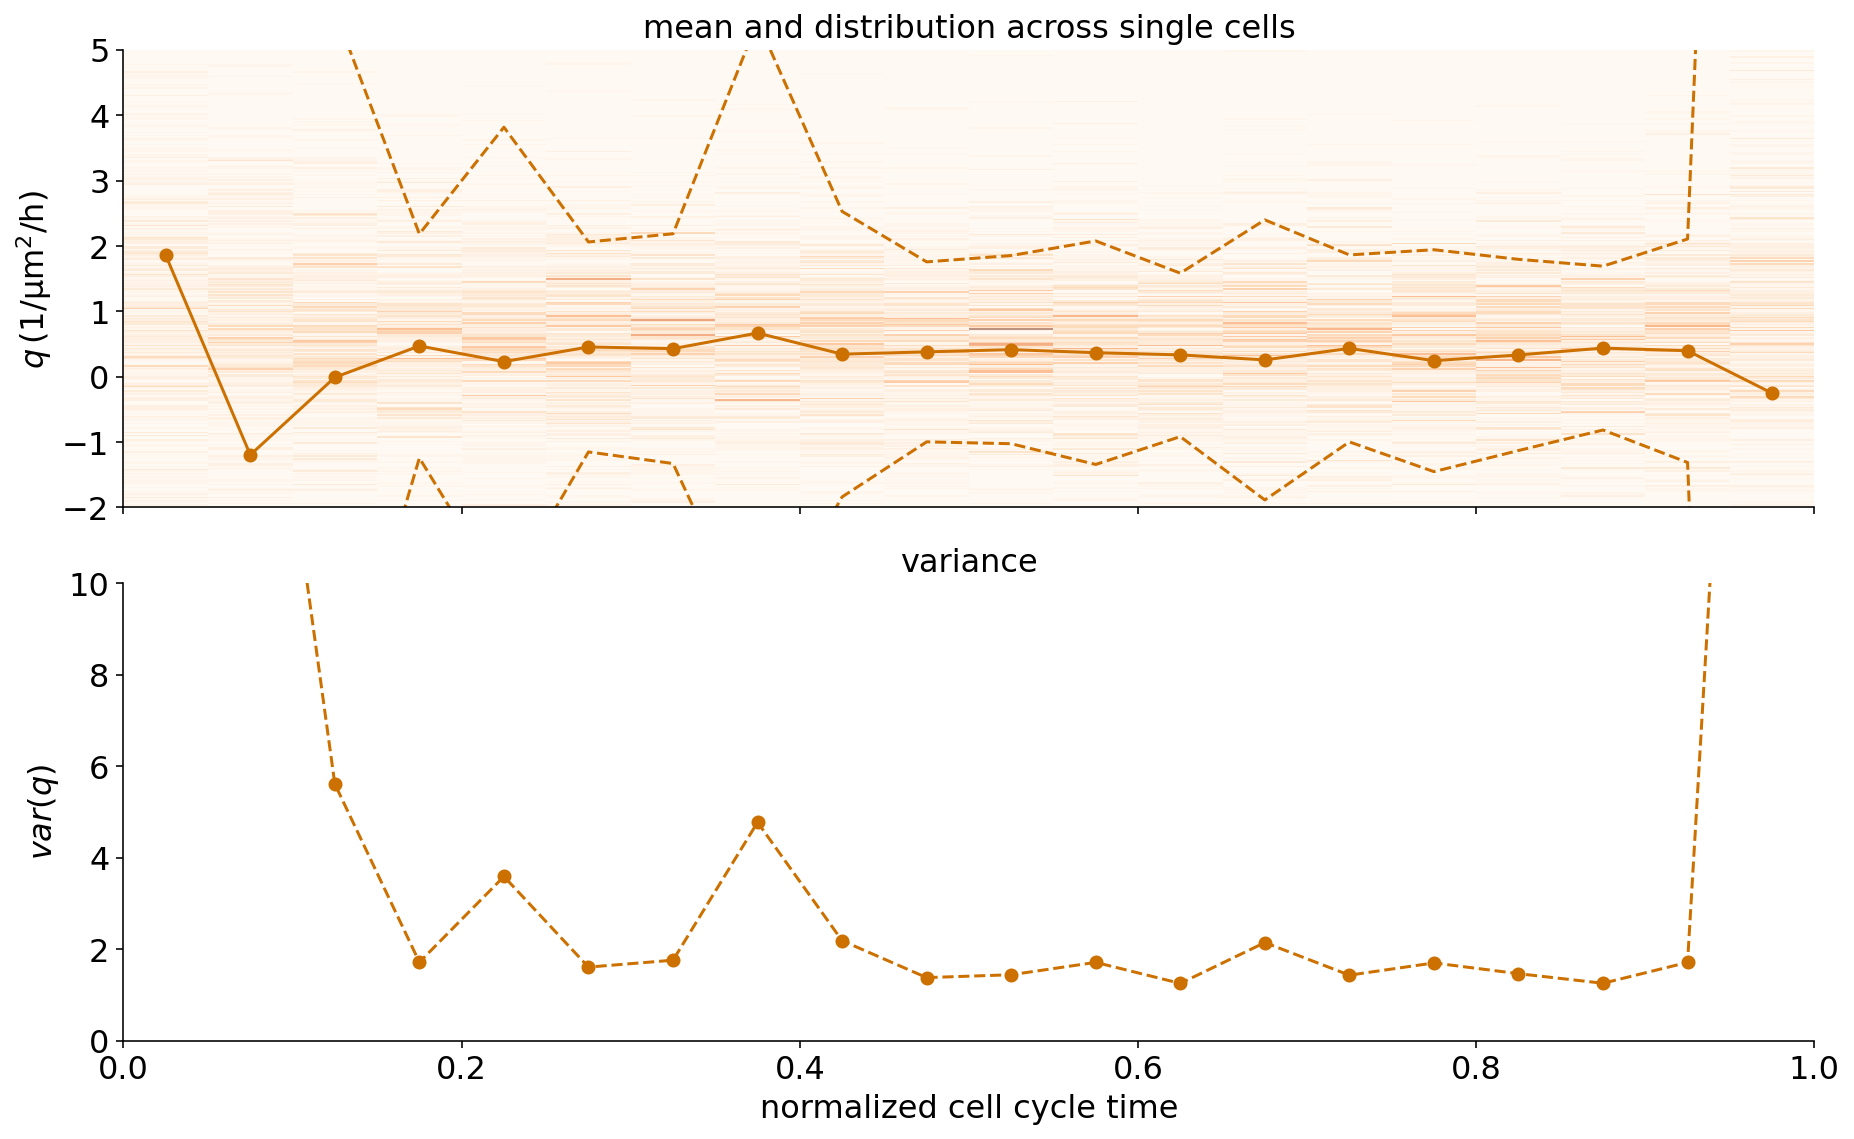

array([<AxesSubplot:>, <AxesSubplot:>], dtype=object)

In [10]:
def plot_cc_variance_q_naive(cells_pred, time_unit=("h", 1), 
                           skip_row=13,
                           xlim=[None, None], 
                           outfile=None, 
                           show=True, 
                           mark_transition=False,
                           color=["tab:blue"]*100,
                        ignore_errors=False):
                         
    fig, axes = plt.subplots(2, 1, figsize=(FULL_SIZE,FULL_HEIGHT*2), sharex=True)

    ax = axes.ravel()


    cells = naive_rate_for_all_cells(cells_pred, 1, naive_production_rate, 0)

    collect_time = []
    for i, cell in enumerate(cells):
        time = np.array(cell.time_naive_rate) / time_unit[1]
        time = (time-time[0])/(time[-1]-time[0])

        collect_time.append(time)
    
    # color_l ="tab:blue"
    # color_q ="tab:orange"
    # color_c ="tab:green"
    color_l ="tab:blue"
    color_q ="#cc7000"
    color_c ="darkgreen"
    
        
    bins=20
    bins_time = bins
    collect_time = np.concatenate(collect_time)

    
    ##########
    collect_mean_q = np.concatenate([cell.naive_rate for cell in cells])
    mean_q, bin_edges,_ = stats.binned_statistic(collect_time, collect_mean_q, statistic='mean', bins=bins)
    std_q, _,_ = stats.binned_statistic(collect_time, collect_mean_q, statistic='std', bins=bins)

    ax[0].plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_q, marker="o", color=color_q)
    ax[0].hist2d(collect_time, collect_mean_q, cmap="Oranges", 
                 bins=[bins_time, np.arange(np.min(collect_mean_q), 
                                 np.max(collect_mean_q), 
                                 np.mean(collect_mean_q)/15 )  ], 
                 density=False, alpha=0.5)
    ax[0].plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_q-std_q, color=color_q, alpha=1, ls="--")
    ax[0].plot(bin_edges[:-1]+np.diff(bin_edges)/2, mean_q+std_q, color=color_q, alpha=1, ls="--")
    
    ax[0].set_title("mean and distribution across single cells")   
    ax[1].set_title(r"variance")   
    
    ##########
    ax[1].plot(bin_edges[:-1]+np.diff(bin_edges)/2, std_q, marker="o", color=color_q, alpha=1, ls="--")


    ax[0].set_ylabel(r"$q\,\mathrm{(1/\mu  m^2/h)}$")   

    ax[1].set_ylabel(r"$var(q)$")

    # ax[0].set_xlabel("normalized cell cycle time")  
    ax[1].set_xlabel("normalized cell cycle time")  
    
    ax[0].set_ylim(-2, 5)
    ax[1].set_ylim(0, 10)

    for a in list(ax) :
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()   
        
    fig.tight_layout()
    
    if outfile != None:
        plt.show()
        fig.savefig(outfile, bbox_inches='tight')
    elif show:
        plt.show()
    fig.clear()
    plt.close(fig)
    return ax


plot_cc_variance_q_naive(esc_data)

In [27]:
# def plot_q_distr_vs_naive(cells, time_unit=("h", 1), 
#                            skip_row=13,
#                            xlim=[None, None], 
#                            outfile=None, 
#                            show=True, 
#                            mark_transition=False,
#                            color=["tab:blue"]*100,
#                         ignore_errors=False):
                         
#     fig, axes = plt.subplots(1,2, figsize=(FULL_SIZE,FULL_HEIGHT*1.2), sharex=True)
#     ax = axes.ravel()
    
    
#     collect_time = []
#     for i, cell in enumerate(cells):
#         time = cell.time
#         time = (time-time[0])/(time[-1]-time[0])
        
#         collect_time.append(time)
    
        
#     bins=20
#     bins_time = bins
#     collect_time = np.concatenate(collect_time)
#     collect_mean_q = np.concatenate([cell.mean_q for cell in cells])
    
#     b1, e1 = np.histogram(collect_mean_q, bins="auto")
#     ax[0].bar( e1[:-1] + np.diff(e1), b1, np.diff(e1), lw = 2, alpha=0.5, color="tab:orange")
#     ax[0].step(e1[:-1] + np.diff(e1), b1, where="mid", lw = 1, alpha=0.5, color="black")

            
#     iqr_pred = np.percentile(collect_mean_q, [25, 75])
    
#     bar_y_position = ax[0].get_ylim()[1]*1.05
#     ax[0].scatter(np.median(collect_mean_q), bar_y_position, color="tab:orange", zorder=100, ec="black")
#     ax[0].hlines(bar_y_position, iqr_pred[0], iqr_pred[1],
#                   lw=3, color="tab:orange", alpha=0.8)    
    
        
#     for jj, n_window in enumerate([1,4,10]):
#         cells_noise = naive_rate_for_all_cells(cells, n_window, naive_production_rate, 0)
#         # cmap =  matplotlib.pyplot.get_cmap("Blues")
#         # color1= cmap((jj)*0.33 +0.33)
#         cmap =  matplotlib.pyplot.get_cmap("viridis_r")
#         color1= cmap((jj)*0.33)
        
#         if jj==0:
#             color1="tab:grey"
        
#         collect_naive_q =  np.concatenate([cell.naive_rate[::n_window] for cell in cells_noise])
        
#         bins=np.arange(np.min(collect_naive_q), np.max(collect_naive_q), np.diff(e1)[0])
        
#         b2, e2 = np.histogram(collect_naive_q, bins=bins)
#         if n_window==1:
#             label="instant."
#         else:
#             label =  label="{:d}".format(n_window+1)
#         ax[1].bar( e2[:-1] + np.diff(e2), b2, np.diff(e2), lw = 2, alpha=0.5, color=color1,label=label)
#         ax[1].step(e2[:-1] + np.diff(e2), b2, where="mid", lw = 1, alpha=0.5, color="black")
#         iqr_naive= np.percentile(collect_naive_q, [25, 75])
    
#         bar_y_position =210-jj*20
    
#         ax[1].scatter(np.median(collect_naive_q),bar_y_position, color=color1, zorder=100, ec="black")
#         ax[1].hlines( bar_y_position, iqr_naive[0],iqr_naive[1],
#                       lw=3, color=color1, alpha=0.8)    
   
#     ax[0].set_ylabel(r"count")   
#     fig.supxlabel(r"production $q\,\mathrm{(1/\mu  m^2/h)}$")   

#     ax[0].set_title("RealTrace")
#     ax[1].set_title("Naive estimates")
#     ax[1].legend(bbox_to_anchor=(1,0.5), loc="center left", title="time average\n(data points)")
    
#     for a in list(ax) :
#         a.spines["top"].set_visible(False)
#         a.spines["right"].set_visible(False)

#         a.spines['right'].set_color('none')
#         a.yaxis.tick_left()

#         a.spines['top'].set_color('none')
#         a.xaxis.tick_bottom()   
        
#     fig.tight_layout()
    
#     ax[0].set_xlim(-2, 4)
    
#     if outfile != None:
#         plt.show()
#         fig.savefig(outfile, bbox_inches='tight')
#     elif show:
#         plt.show()
#     fig.clear()
#     plt.close(fig)
#     return ax


# plot_q_distr_vs_naive(esc_data,
#                         outfile="../../figures_for_method_paper/supp/esc/esc_production_hist.pdf")


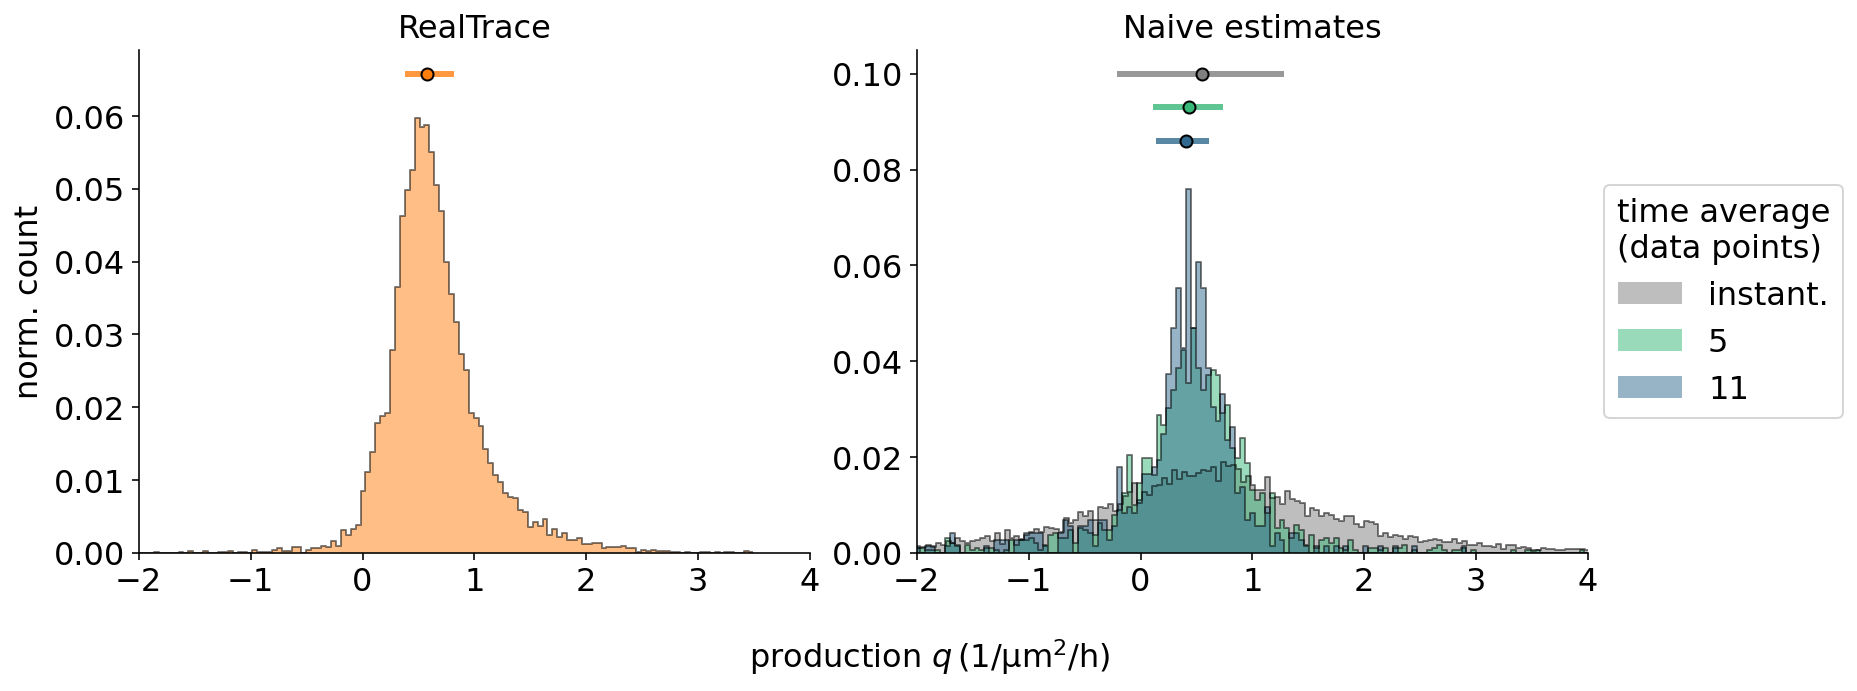

array([<AxesSubplot:>, <AxesSubplot:>], dtype=object)

In [28]:
def plot_q_distr_vs_naive(cells, time_unit=("h", 1), 
                           skip_row=13,
                           xlim=[None, None], 
                           outfile=None, 
                           show=True, 
                           mark_transition=False,
                           color=["tab:blue"]*100,
                        ignore_errors=False):
                         
    fig, axes = plt.subplots(1,2, figsize=(FULL_SIZE,FULL_HEIGHT*1.2), sharex=True)
    ax = axes.ravel()
    
    
    collect_time = []
    for i, cell in enumerate(cells):
        time = cell.time
        time = (time-time[0])/(time[-1]-time[0])
        
        collect_time.append(time)
    
        
    bins=20
    bins_time = bins
    collect_time = np.concatenate(collect_time)
    collect_mean_q = np.concatenate([cell.mean_q for cell in cells])
    
    b1, e1 = np.histogram(collect_mean_q, bins="auto")
    b1 = np.array(b1)/np.sum(b1)
    
    ax[0].bar( e1[:-1] + np.diff(e1), b1, np.diff(e1), lw = 2, alpha=0.5, color="tab:orange")
    ax[0].step(e1[:-1] + np.diff(e1), b1, where="mid", lw = 1, alpha=0.5, color="black")

            
    iqr_pred = np.percentile(collect_mean_q, [25, 75])
    
    bar_y_position = ax[0].get_ylim()[1]*1.05
    ax[0].scatter(np.median(collect_mean_q), bar_y_position, color="tab:orange", zorder=100, ec="black")
    ax[0].hlines(bar_y_position, iqr_pred[0], iqr_pred[1],
                  lw=3, color="tab:orange", alpha=0.8)    
    
        
    for jj, n_window in enumerate([1,4,10]):
        cells_noise = naive_rate_for_all_cells(cells, n_window, naive_production_rate, 0)
        # cmap =  matplotlib.pyplot.get_cmap("Blues")
        # color1= cmap((jj)*0.33 +0.33)
        cmap =  matplotlib.pyplot.get_cmap("viridis_r")
        color1= cmap((jj)*0.33)
        
        if jj==0:
            color1="tab:grey"
        
        collect_naive_q =  np.concatenate([cell.naive_rate[::n_window] for cell in cells_noise])
        
        bins=np.arange(np.min(collect_naive_q), np.max(collect_naive_q), np.diff(e1)[0])
        
        b2, e2 = np.histogram(collect_naive_q, bins=bins)
        if n_window==1:
            label="instant."
        else:
            label =  label="{:d}".format(n_window+1)
        b2 = np.array(b2)/np.sum(b2)
        
        ax[1].bar( e2[:-1] + np.diff(e2), b2, np.diff(e2), lw = 2, alpha=0.5, color=color1,label=label)
        ax[1].step(e2[:-1] + np.diff(e2), b2, where="mid", lw = 1, alpha=0.5, color="black")
        iqr_naive= np.percentile(collect_naive_q, [25, 75])
    
        bar_y_position =0.1-jj*0.007
    
        ax[1].scatter(np.median(collect_naive_q),bar_y_position, color=color1, zorder=100, ec="black")
        ax[1].hlines( bar_y_position, iqr_naive[0],iqr_naive[1],
                      lw=3, color=color1, alpha=0.8)    
   
    ax[0].set_ylabel(r"norm. count")   
    fig.supxlabel(r"production $q\,\mathrm{(1/\mu  m^2/h)}$")   

    ax[0].set_title("RealTrace")
    ax[1].set_title("Naive estimates")


    plt.rcParams['legend.title_fontsize'] = MEDIUM_SIZE

    lg = ax[1].legend(bbox_to_anchor=(1,0.5), loc="center left", title="time average\n(data points)")

    
    for a in list(ax) :
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()   
        
    fig.tight_layout()
    
    ax[0].set_xlim(-2, 4)
    
    if outfile != None:
        plt.show()
        fig.savefig(outfile, bbox_inches='tight')
    elif show:
        plt.show()
    fig.clear()
    plt.close(fig)
    return ax


plot_q_distr_vs_naive(esc_data,
                        outfile="../../figures_for_method_paper/supp/esc/esc_production_hist.pdf")


In [ ]:
cell_cycle_times = [cell.time[-1]-cell.time[0] for cell in esc_data]
plt.hist(cell_cycle_times, bins="auto")
print(np.mean(cell_cycle_times))

In [ ]:
def legend_without_duplicate_labels(ax=None, sorting=None):
    def find_str(arr, s):
        for i,a in enumerate(arr):
            if a==s:
                return i
            

    if isinstance(ax,np.ndarray):
        handles = []
        labels = []
        for a in ax.ravel():
            h, l = a.get_legend_handles_labels()
            handles.append(h)
            labels.append(l)
        handles = np.concatenate(handles)
        labels = np.concatenate(labels)
            
    else:
        handles, labels = ax.get_legend_handles_labels()
    
    if sorting=="auto":
        sorting = np.argsort(labels)
        handles = np.array(handles)[sorting]
        labels = np.array(labels)[sorting]
    elif sorting!=None:
        idx_sorting = []
        for s in sorting:
            idx_sorting.append(find_str(labels,s))
        handles = np.array(handles)[idx_sorting]
        labels = np.array(labels)[idx_sorting]

    unique = [(h, l) for i, (h, l) in enumerate(zip(handles, labels)) if l not in labels[:i]]
    return zip(*unique)

def compare_sc_pred_vs_naive(cells, n_cells, outfile=None):
                         
    n_col = 2
    fig, axes = plt.subplots(n_cells,n_col, figsize=(FULL_SIZE,FULL_HEIGHT*n_cells*0.5), sharey=True, sharex=True)
    ax = axes.ravel()
        
    np.random.seed(0)
    cells_idx = np.random.choice(np.arange(len(cells)), n_cells, replace=False)
    
    for i, idx in enumerate(cells_idx):
        time = cells[idx].time - cells[idx].time[0]
        ax[n_col*i].plot(time, cells[idx].mean_q, color="tab:orange")
        ax[n_col*i].fill_between(time, cells[idx].mean_q-np.sqrt(cells[idx].cov_qq), cells[idx].mean_q+np.sqrt(cells[idx].cov_qq), 
                    color="tab:orange", alpha=0.2)
    
        ylim0 =-6
        ylim1 =6
        ax[n_col*i].set_ylim(ylim0, ylim1)
        ax[n_col*i+1].set_ylim(ylim0, ylim1)
        
    for jj, n_window in enumerate([1,4,10]):
        cells_noise = naive_rate_for_all_cells(cells, n_window, naive_production_rate, 0)
        cmap =  matplotlib.pyplot.get_cmap("viridis_r")
        color1= cmap((jj)*0.33)
        # color1= cmap((jj)*0.33 +0.33)
        print((jj)*0.33 +0.33)
        if jj==0:
            color1="tab:grey"

        
        for i, idx in enumerate(cells_idx):
            time = cells_noise[idx].time_naive_rate - cells[idx].time[0]
            if n_window==1:
                label="instant."
            else:
                label =  label="{:d}".format(n_window+1)

            if n_window>1:
                ax[n_col*i+1].plot(time, cells_noise[idx].naive_rate, color=color1,  alpha=0.8, label=label )
                ax[n_col*i+1].scatter(time[::n_window], cells_noise[idx].naive_rate[::n_window], color=color1)
            else:
                ax[n_col*i+1].plot(time, cells_noise[idx].naive_rate, color=color1,  alpha=0.8, label=label )
                
    ax[0].set_title("RealTrace")
    ax[1].set_title("Naive estimates")
    ax[1].legend(*legend_without_duplicate_labels(ax), bbox_to_anchor=(1,0.5), loc="center left", title="time average\n(data points)", ncol=1)
    
    ax[0].xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=3))
    ax[0].yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=3))
    # ax[0].yaxis.set_minor_locator(matplotlib.ticker.MultipleLocator(base=1))
        
    fig.supxlabel("time (h)")
    fig.supylabel(r"production $q\,\mathrm{(1/\mu  m^2/h)}$")   
    
    for a in list(ax) :
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()   
        
    fig.tight_layout()
    
    
    if outfile != None:
        plt.show()
        fig.savefig(outfile, bbox_inches='tight')
    plt.show()
    fig.clear()
    plt.close(fig)
    return ax


compare_sc_pred_vs_naive(cells, 5,
                        outfile="../../figures_for_method_paper/supp/esc/single_cell_production.pdf")




In [ ]:
legend_without_duplicate_labels

In [ ]:
def compare_sc_pred_vs_naive_size_g(cells, n_cells, outfile=None):
                         
    fig, axes = plt.subplots(n_cells,2, figsize=(FULL_SIZE,FULL_HEIGHT*n_cells*0.5), sharey=False, sharex=True)
    ax = axes.ravel()
        
    np.random.seed(0)
    cells_idx = np.random.choice(np.arange(len(cells)), n_cells, replace=False)
    
    for i, idx in enumerate(cells_idx):
        time = cells[idx].time - cells[idx].time[0]
       
        ax[2*i].plot(time, cells[idx].mean_x, color="tab:orange", label="RealTrace")
        ax[2*i].fill_between(time, cells[idx].mean_x-np.sqrt(cells[idx].cov_xx), cells[idx].mean_x+np.sqrt(cells[idx].cov_xx), 
                    color="tab:orange", alpha=0.2)
        ax[2*i].plot(time, cells[idx].log_length,'o', markersize=4, mfc='none', color="tab:grey", alpha=1, label="raw")
        
        ax[2*i+1].plot(time, cells[idx].mean_g/1e5, color="tab:orange")
        ax[2*i+1].fill_between(time, (cells[idx].mean_g-np.sqrt(cells[idx].cov_gg))/1e5, (cells[idx].mean_g+np.sqrt(cells[idx].cov_gg))/1e5, 
                    color="tab:orange", alpha=0.2)
        ax[2*i+1].plot(time, cells[idx].gfp/1e5,'o', markersize=4, mfc='none', color="tab:grey", alpha=1)

        
    ax[0].set_title("log area\n$x\,\mathrm{(\mu  m^2)}$")
    ax[1].set_title("total fluorescence\n$g\,(\mathrm{10^5})$")

    ax[0].legend(bbox_to_anchor=(1,0), loc="lower right")
    
    ax[0].xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=3))
        
    fig.supxlabel("time (h)")
    
    for a in list(ax) :
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()   
        
    fig.tight_layout()
    
    
    if outfile != None:
        plt.show()
        fig.savefig(outfile, bbox_inches='tight')
    plt.show()
    fig.clear()
    plt.close(fig)
    return ax


compare_sc_pred_vs_naive_size_g(cells, 5, outfile="../../figures_for_method_paper/supp/esc/single_cell_traces.pdf")




In [ ]:

def bin_with_error_bars(means, variances, n_bins=1000, return_edges=True, ignore_errors=False):
    if ignore_errors:
        return np.histogram(means, bins="auto")
    left = np.min(means) - 2*np.sqrt(variances[np.argmin(means)])
    right = np.max(means) + 2*np.sqrt(variances[np.argmax(means)])
    
    _,bin_edges = np.histogram(means, bins=np.linspace(left, right, n_bins))
    
    bin_c = bin_edges[:-1] +np.diff(bin_edges)/2
    weight = np.zeros_like(bin_c)
    for i, m in enumerate(means):
        weight += special.erf( (bin_edges[1:]-m)/np.sqrt(2*variances[i]) ) - special.erf( (bin_edges[:-1]-m)/np.sqrt(2*variances[i]) )
    if return_edges:
        return weight, bin_edges
    else:
        return weight, bin_c


    
color=["tab:blue", "tab:orange", "tab:green", "tab:olive"]*100


def plot_predictions_ecs(cells, cell_idx, time_unit=("h", 1), 
                           skip_row=13,
                           xlim=[None, None], 
                           outfile=None, 
                           show=True, 
                           mark_transition=False,
                           color=["tab:blue"]*100,
                        ignore_errors=False):
                         
    fig, axes = plt.subplots(2, 2, figsize=(FULL_SIZE,FULL_HEIGHT*2), sharex=True)

    axes = axes.transpose()
    ax = axes.ravel()

    s = 10
    lw = 1.5
    
    time = np.concatenate([cell.time for cell in cells])
    
    ### LAMBDA
    l_coll = np.concatenate([cell.mean_l for cell in cells])
    l_var_coll = np.concatenate([cell.cov_ll for cell in cells])
    
    ### Q
    q_coll = np.concatenate([cell.mean_q for cell in cells])
    q_var_coll = np.concatenate([cell.cov_qq for cell in cells])
    
    for i, cell in enumerate(cells):
        if i not in cell_idx:
            continue
        time = np.array(cell.time) / time_unit[1]
        time -= time[0]
        prediction_color = color[0]
        rate_color = color[0]
        color = color[1:]

        ax[0].plot(time, cell.log_length, 'o', markersize=4, mfc='none', color="tab:grey", alpha=1)
        ax[0].plot(time, cell.mean_x, color=prediction_color, lw=lw)
        ax[0].fill_between(time, cell.mean_x-np.sqrt(cell.cov_xx), cell.mean_x+np.sqrt(cell.cov_xx), 
                    color=prediction_color, alpha=0.2)
        
        
        ax[1].plot(time, cell.gfp, 'o', markersize=4, mfc='none', color="tab:grey", alpha=1)
        ax[1].plot(time, cell.mean_g, color=prediction_color, lw=lw)
        ax[1].fill_between(time, cell.mean_g-np.sqrt(cell.cov_gg), cell.mean_g+np.sqrt(cell.cov_gg), 
                    color=prediction_color, alpha=0.2)
        
        ax[2].plot(time, cell.mean_l, color=rate_color, lw=lw)
        ax[2].fill_between(time, cell.mean_l-np.sqrt(cell.cov_ll), cell.mean_l+np.sqrt(cell.cov_ll), 
                    color=rate_color, alpha=0.2)

        ax[3].plot(time, cell.mean_q, color=rate_color, lw=lw)
        ax[3].fill_between(time, cell.mean_q-np.sqrt(cell.cov_qq), cell.mean_q+np.sqrt(cell.cov_qq), 
                    color=rate_color, alpha=0.2)

    for i in range(4):
        ax[i].set_xlim(xlim)
        
    if mark_transition:
        for a in ax:
            a_ylim = a.get_ylim()
            a_xlim = a.get_xlim()
            a.add_patch(plt.Rectangle((12, a_ylim[0]), a_xlim[1]-12, a_ylim[1], 
                                      transform=a.transData, 
                                      color='lightgrey', 
                                      alpha=0.3))
                

    ax[0].set_ylabel("log(area/$\mathrm{\mu m^2}$) x")   
    ax[1].set_ylabel("$g$ (a.u.)")   
    ax[2].set_ylabel(r"$\lambda$ (1/h)")   
    ax[3].set_ylabel(r"$q$ $\mathrm{(1/\mu  m^2/h)}$")   

    # ax[0].set_ylabel("$x$ $\mathrm{(\mu m^2)}$ ")   
    # ax[1].set_ylabel("$g$ (a.u.)")   
    # ax[2].set_ylabel(r"$\lambda$ (1/h)")   
    # ax[3].set_ylabel(r"$q$ $\mathrm{(a.u./\mu m^2/h)}$")   



    # ax[0].set_xlabel("time ({:s})".format(time_unit[0]))  
    ax[1].set_xlabel("time ({:s})".format(time_unit[0]))  
    # ax[2].set_xlabel("time ({:s})".format(time_unit[0]))  
    ax[3].set_xlabel("time ({:s})".format(time_unit[0]))  
    
    
    ax[1].ticklabel_format(axis='y', style='scientific', scilimits=[-2,2], useMathText=True)
    ax[3].ticklabel_format(axis='y', style='scientific', scilimits=[-2,2], useMathText=True)

    ax2_lim = ax[2].get_ylim()
    ax3_lim = ax[3].get_ylim()
       
    #################### HIST
    ax_histy = ax[2].inset_axes([1.06, 0, 0.25, 1], sharey=ax[2])
    ax_histy.tick_params(direction='in', labelleft=False)
    # ax_histy.set_title("distribution")
    # ax_histy.set_xlabel("frequency")
        
    hist, bin_edges = bin_with_error_bars(np.ravel(l_coll), np.ravel(l_var_coll),ignore_errors=ignore_errors)
    bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2

    ax_histy.barh(bin_edges[:-1], hist, height=np.diff(bin_edges),
            edgecolor=None, align="edge", color="grey", alpha=0.2)
    ax_histy.step(hist, bin_edges[:-1], color="black", alpha=0.3)
    ax_histy.set_xticks([])
  
    #################### HIST
    ax_histy2 = ax[3].inset_axes([1.06, 0, 0.25, 1], sharey=ax[3], sharex=ax_histy)
    ax_histy2.tick_params(direction='in', labelleft=False)
    # ax_histy.set_title("distribution")
    # ax_histy2.set_xlabel("frequency")
        
    hist, bin_edges = bin_with_error_bars(np.ravel(q_coll), np.ravel(q_var_coll), ignore_errors=ignore_errors)
    bin_centers = bin_edges[:-1] + np.diff(bin_edges)/2

    ax_histy2.barh(bin_edges[:-1], hist, height=np.diff(bin_edges),
            edgecolor=None, align="edge", color="grey", alpha=0.2)
    ax_histy2.step(hist, bin_edges[:-1], color="black", alpha=0.3)
    ax_histy2.set_xticks([])

        
    ax[2].set_ylim(ax2_lim)
    ax[3].set_ylim(ax3_lim)
    
    fig.tight_layout(h_pad=0)

    for a in list(ax) + [ax_histy,ax_histy2]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()    
    
    if outfile != None:
        plt.show()
        fig.savefig(outfile, bbox_inches='tight')
    elif show:
        plt.show()
    fig.clear()
    plt.close(fig)
    return ax


plot_predictions_ecs(cells, 
                     np.arange(0, len(cells)), 
                    color=color,
                    ignore_errors=True)
